In [1]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    learning_curve
)
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# The uploaded file contains CSV data despite its .xls extension.
file_path = "materials_project_cleaning/materials_cleaned.csv"

if not os.path.exists(file_path):
    raise FileNotFoundError(
        f"Dataset not found: {file_path}\n"
        "Place the dataset in your Jupyter Notebook folder."
    )

df = pd.read_csv(file_path, low_memory=False)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDataset information:")
df.info()

Dataset loaded successfully!
Dataset shape: (10000, 5)

Column names:
['material_id', 'chemical_formula', 'crystal_system', 'space_group', 'full_structure']


,material_id,chemical_formula,crystal_system,space_group,full_structure
0,mp-3346392,CaMg(CO3)2,Monoclinic,P2_1/c,"{""@module"": ""pymatgen.core.structure"", ""@class..."
1,mp-3346394,Ca2Mg(CO3)3,Monoclinic,C2/c,"{""@module"": ""pymatgen.core.structure"", ""@class..."
2,mp-3346398,CaMg(CO3)2,Triclinic,P-1,"{""@module"": ""pymatgen.core.structure"", ""@class..."
3,mp-3346400,Li4Mg3Cl10,Monoclinic,Cm,"{""@module"": ""pymatgen.core.structure"", ""@class..."
4,mp-3346401,CaMg3(CO3)4,Triclinic,P-1,"{""@module"": ""pymatgen.core.structure"", ""@class..."



Missing values:


,Missing Values
material_id,0
chemical_formula,0
crystal_system,0
space_group,0
full_structure,0



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   material_id       10000 non-null  object
 1   chemical_formula  10000 non-null  object
 2   crystal_system    10000 non-null  object
 3   space_group       10000 non-null  object
 4   full_structure    10000 non-null  object
dtypes: object(5)
memory usage: 390.8+ KB


Cleaned dataset shape: (7301, 2)

Crystal system classes:


,Number of Materials
crystal_system,
Triclinic,3043
Monoclinic,1732
Orthorhombic,734
Trigonal,696
Cubic,596
Tetragonal,431
Hexagonal,69



Class proportions:


,Percentage (%)
crystal_system,
Triclinic,41.68
Monoclinic,23.72
Orthorhombic,10.05
Trigonal,9.53
Cubic,8.16
Tetragonal,5.90
Hexagonal,0.95


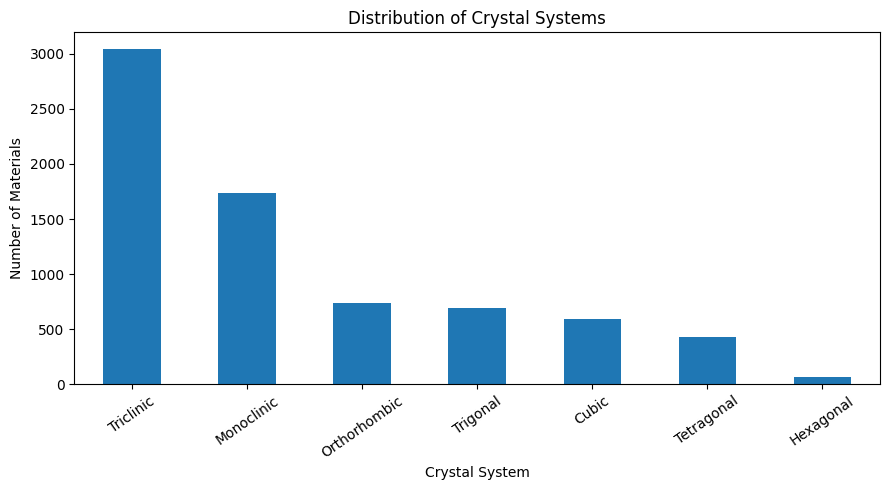

In [3]:
target_column = "crystal_system"
feature_column = "chemical_formula"

required_columns = [feature_column, target_column]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns are missing: {missing_columns}"
    )

# Keep only the required columns to reduce memory usage.
data = df[required_columns].copy()

# Remove missing and invalid values.
data = data.dropna(subset=required_columns)

data[feature_column] = (
    data[feature_column].astype(str).str.strip()
)
data[target_column] = (
    data[target_column].astype(str).str.strip()
)

data = data[
    (data[feature_column] != "") &
    (data[target_column] != "")
]

# Remove exact duplicate feature-target pairs.
data = data.drop_duplicates(
    subset=[feature_column, target_column]
).reset_index(drop=True)

X = data[feature_column]
y = data[target_column]

print("Cleaned dataset shape:", data.shape)
print("\nCrystal system classes:")
display(y.value_counts().to_frame("Number of Materials"))

print("\nClass proportions:")
display(
    (y.value_counts(normalize=True) * 100)
    .round(2)
    .to_frame("Percentage (%)")
)

# Visualize target class distribution.
y.value_counts().plot(
    kind="bar",
    figsize=(9, 5),
    title="Distribution of Crystal Systems"
)
plt.xlabel("Crystal System")
plt.ylabel("Number of Materials")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

In [4]:
# Every class must have enough samples for the selected CV folds.
class_counts = y.value_counts()
n_splits = min(5, int(class_counts.min()))

if n_splits < 2:
    raise ValueError(
        "At least one crystal-system class has fewer than "
        "2 samples. Stratified cross-validation is not possible."
    )

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Number of folds:", n_splits)

cv = StratifiedKFold(
    n_splits=n_splits,
    shuffle=True,
    random_state=RANDOM_STATE
)

print("\nStratified K-Fold created successfully.")

Training samples: 5840
Testing samples: 1461
Number of folds: 5

Stratified K-Fold created successfully.


In [5]:
models = {
    "Dummy Baseline": DummyClassifier(
        strategy="most_frequent"
    ),

    "Logistic Regression": LogisticRegression(
        max_iter=1500,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Linear SVM": LinearSVC(
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Multinomial Naive Bayes": MultinomialNB(
        alpha=0.5
    )
}

pipelines = {}

for name, model in models.items():
    pipelines[name] = Pipeline([
        (
            "vectorizer",
            TfidfVectorizer(
                analyzer="char",
                ngram_range=(1, 3),
                lowercase=False,
                min_df=2,
                sublinear_tf=True
            )
        ),
        ("classifier", model)
    ])

print("Created", len(pipelines), "machine learning pipelines.")

for name in pipelines:
    print("-", name)

Created 4 machine learning pipelines.
- Dummy Baseline
- Logistic Regression
- Linear SVM
- Multinomial Naive Bayes


In [6]:
scoring = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro"
}

results = []

for name, pipeline in pipelines.items():
    print(f"Evaluating: {name}")

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False,
        error_score="raise"
    )

    results.append({
        "Model": name,
        "CV Accuracy (%)":
            scores["test_accuracy"].mean() * 100,
        "Accuracy Std (%)":
            scores["test_accuracy"].std() * 100,
        "Macro Precision (%)":
            scores["test_precision_macro"].mean() * 100,
        "Macro Recall (%)":
            scores["test_recall_macro"].mean() * 100,
        "Macro F1 (%)":
            scores["test_f1_macro"].mean() * 100
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Macro F1 (%)",
    ascending=False
).reset_index(drop=True)

print("\nCROSS-VALIDATION PERFORMANCE TABLE")
display(results_df.round(3))

print("Best model based on CV Macro F1:",
      results_df.iloc[0]["Model"])

Evaluating: Dummy Baseline
Evaluating: Logistic Regression
Evaluating: Linear SVM
Evaluating: Multinomial Naive Bayes

CROSS-VALIDATION PERFORMANCE TABLE


,Model,CV Accuracy (%),Accuracy Std (%),Macro Precision (%),Macro Recall (%),Macro F1 (%)
0,Logistic Regression,54.315,1.017,42.858,48.195,43.784
1,Linear SVM,56.027,1.336,41.698,44.776,42.680
2,Multinomial Naive Bayes,55.137,1.106,42.468,37.070,36.603
3,Dummy Baseline,41.678,0.034,5.954,14.286,8.405


Best model based on CV Macro F1: Logistic Regression


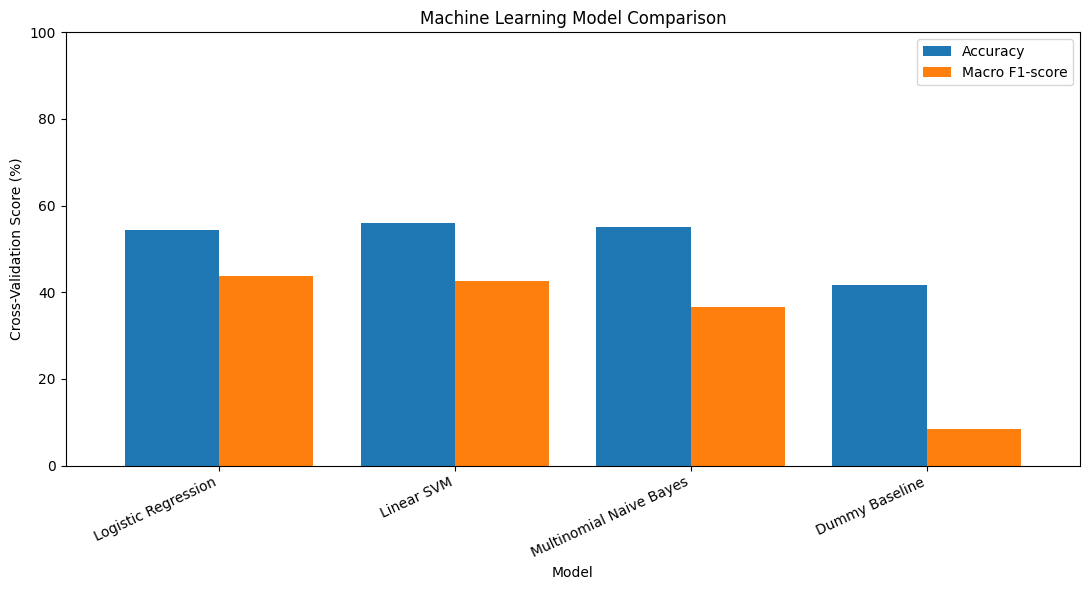

In [7]:
plot_data = results_df.set_index("Model")[
    ["CV Accuracy (%)", "Macro F1 (%)"]
]

ax = plot_data.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.8
)

ax.set_title("Machine Learning Model Comparison")
ax.set_xlabel("Model")
ax.set_ylabel("Cross-Validation Score (%)")
ax.set_ylim(0, 100)
ax.legend(["Accuracy", "Macro F1-score"])
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

Selected model: Logistic Regression


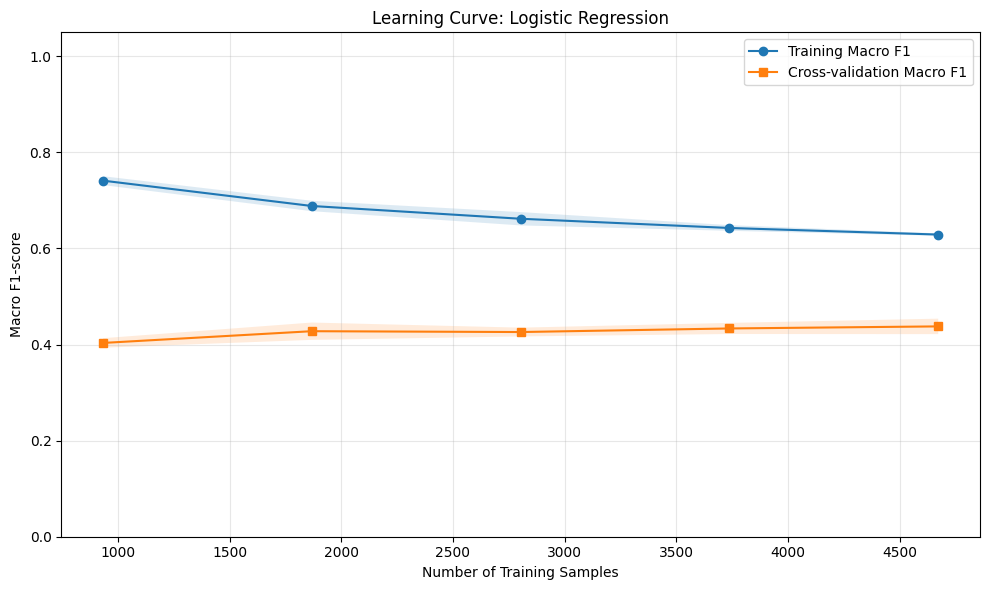

In [8]:
best_model_name = results_df.iloc[0]["Model"]
best_pipeline = pipelines[best_model_name]

print("Selected model:", best_model_name)

# Learning curves can be expensive on large datasets.
# Set fewer training sizes and use all available CV folds.
train_sizes = np.linspace(0.2, 1.0, 5)

sizes, train_scores, validation_scores = learning_curve(
    estimator=best_pipeline,
    X=X_train,
    y=y_train,
    train_sizes=train_sizes,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1,
    shuffle=True,
    random_state=RANDOM_STATE,
    error_score="raise"
)

train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)
validation_mean = validation_scores.mean(axis=1)
validation_std = validation_scores.std(axis=1)

plt.figure(figsize=(10, 6))

plt.plot(
    sizes, train_mean,
    marker="o",
    label="Training Macro F1"
)
plt.plot(
    sizes, validation_mean,
    marker="s",
    label="Cross-validation Macro F1"
)

plt.fill_between(
    sizes,
    train_mean - train_std,
    train_mean + train_std,
    alpha=0.15
)
plt.fill_between(
    sizes,
    validation_mean - validation_std,
    validation_mean + validation_std,
    alpha=0.15
)

plt.title(f"Learning Curve: {best_model_name}")
plt.xlabel("Number of Training Samples")
plt.ylabel("Macro F1-score")
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [9]:
best_pipeline.fit(X_train, y_train)

y_pred = best_pipeline.predict(X_test)

print("BEST MODEL:", best_model_name)
print("\nTEST SET PERFORMANCE")
print("-" * 45)

print(
    f"Accuracy:  {accuracy_score(y_test, y_pred) * 100:.2f}%"
)
print(
    f"Precision: {precision_score(y_test, y_pred, average='macro', zero_division=0) * 100:.2f}%"
)
print(
    f"Recall:    {recall_score(y_test, y_pred, average='macro', zero_division=0) * 100:.2f}%"
)
print(
    f"Macro F1:  {f1_score(y_test, y_pred, average='macro', zero_division=0) * 100:.2f}%"
)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

BEST MODEL: Logistic Regression

TEST SET PERFORMANCE
---------------------------------------------
Accuracy:  57.08%
Precision: 46.27%
Recall:    53.14%
Macro F1:  47.92%

Classification Report:
              precision    recall  f1-score   support

       Cubic       0.70      0.85      0.77       119
   Hexagonal       0.18      0.36      0.24        14
  Monoclinic       0.54      0.51      0.52       347
Orthorhombic       0.26      0.29      0.27       147
  Tetragonal       0.25      0.47      0.32        86
   Triclinic       0.92      0.63      0.75       609
    Trigonal       0.40      0.62      0.48       139

    accuracy                           0.57      1461
   macro avg       0.46      0.53      0.48      1461
weighted avg       0.65      0.57      0.59      1461



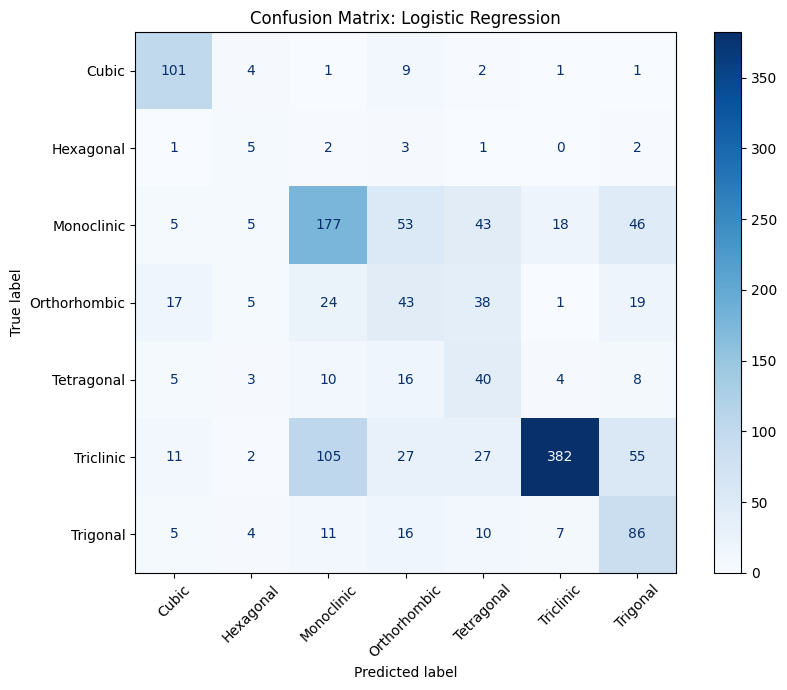

In [10]:
fig, ax = plt.subplots(figsize=(9, 7))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    normalize=None,
    xticks_rotation=45,
    cmap="Blues",
    ax=ax
)

ax.set_title(f"Confusion Matrix: {best_model_name}")
plt.tight_layout()
plt.show()

In [11]:
# Save the trained pipeline, including its text vectorizer.
joblib.dump(
    best_pipeline,
    "best_crystal_system_model.joblib"
)

# Save comparison and test predictions.
results_df.to_csv(
    "cross_validation_results.csv",
    index=False
)

predictions_df = pd.DataFrame({
    "Chemical Formula": X_test.values,
    "Actual Crystal System": y_test.values,
    "Predicted Crystal System": y_pred
})

predictions_df.to_csv(
    "crystal_system_predictions.csv",
    index=False
)

print("Saved successfully:")
print("1. best_crystal_system_model.joblib")
print("2. cross_validation_results.csv")
print("3. crystal_system_predictions.csv")

Saved successfully:
1. best_crystal_system_model.joblib
2. cross_validation_results.csv
3. crystal_system_predictions.csv


In [12]:
loaded_model = joblib.load(
    "best_crystal_system_model.joblib"
)

new_formula = ["CaMg(CO3)2", "SiO2", "Al2O3"]

predictions = loaded_model.predict(new_formula)

prediction_results = pd.DataFrame({
    "Chemical Formula": new_formula,
    "Predicted Crystal System": predictions
})

display(prediction_results)

,Chemical Formula,Predicted Crystal System
0,CaMg(CO3)2,Trigonal
1,SiO2,Orthorhombic
2,Al2O3,Hexagonal
